1. Imports

In [1]:
#imports
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_swiss_roll

#fix the random seed so that every run produces exactly the same data
RANDOM_STATE = 0 

print("Libraries loaded successfully")


Libraries loaded successfully


2. Swiss roll data (N = 1000)

Shape of X: (1000, 3)
First 3 points:
 [[ -8.85708287  12.45048569  -4.38885338]
 [  5.0569229    0.21133761 -10.2760021 ]
 [ -5.88799247   9.99235011  -8.56459157]]


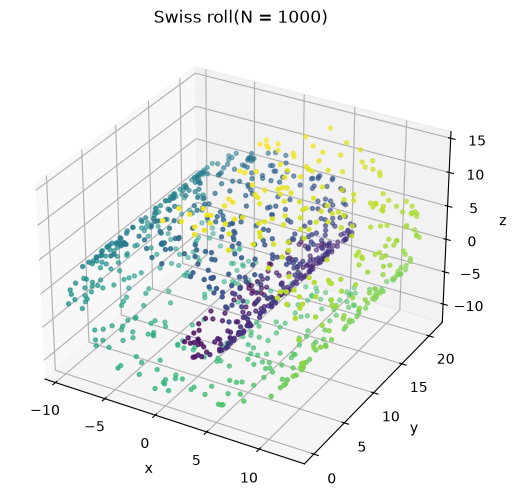

In [2]:
#generate the swiss roll dataset
N = 1000 #number of data points (same as in the paper)

#X : the 3D coordinates of each point
#t : the posotion of each point along the roll 
X, t = make_swiss_roll(n_samples = N, noise=0.0, random_state= RANDOM_STATE)

print("Shape of X:", X.shape)
print("First 3 points:\n", X[:3])

#3D scatter plot of the data, colored by the hidden coordinate t
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
ax.scatter(X[:, 0], X[:, 1],X[:, 2],  c = t, cmap = "viridis", s = 8)
ax.set_title(f"Swiss roll(N = {N})")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
plt.show()

3. Isomap Step 1: Neighborhood graph

In [3]:
#Step 1 - Construct the neighborhood graph
from sklearn.neighbors import kneighbors_graph
from scipy.sparse.csgraph import connected_components

#number of nearest neighbors
K = 7 

#build the K-nearest-neighbor graph
G = kneighbors_graph(X, n_neighbors = K, mode = "distance")

#make the graph symmetric
G = G.maximum(G.T)

#number of edges
print("Number of points:", G.shape[0])
print("Number of edges: ", G.nnz // 2)

#check whether the graph is connected
n_components, labels = connected_components(G, directed = False)
print("Connected componenets:", n_components)

Number of points: 1000
Number of edges:  4107
Connected componenets: 1


4. Visualization of the neighborhood graph

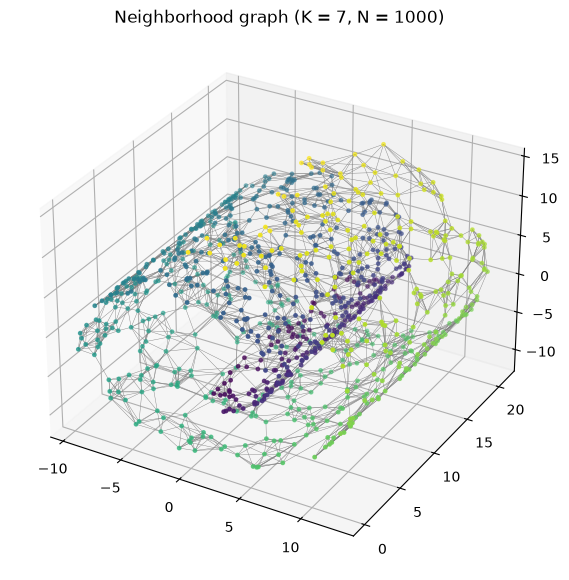

In [4]:
#visualize the neighborhood graph 
from mpl_toolkits.mplot3d.art3d import Line3DCollection

#get all pairs that are connected by an edge
rows, cols = G.nonzero()

#build a list of line segments, one per edge
edges = [(X[i], X[j]) for i, j in zip(rows, cols) if i < j]

fig = plt.figure(figsize = (8, 7))
ax = fig.add_subplot(projection="3d")

#draw the edges as thin gray lines
ax.add_collection3d(Line3DCollection(edges, colors="gray", linewidths=0.3))

#draw the points on top, colored by the hidden coordinate t 
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=t, cmap="viridis", s=6)

ax.set_title(f"Neighborhood graph (K = {K}, N = {N})")
plt.show()

5. Isomap Step 2 : Shortest-path (geodesic) distances

In [5]:
#Step 2 - Compute shortest paths in the graph
from scipy.sparse.csgraph import shortest_path
from scipy.spatial.distance import pdist, squareform

#graph distances D_G : we use Dijkstra algorith to compute the distance
D_G = shortest_path(G, method= "D", directed = False)

#Straight-line Euclidean distances D_X in the 3D input space
D_X =  squareform(pdist(X))

print("Shape of D_G:", D_G.shape)
print("Any infinite distances?", np.isinf(D_G).any())

#find the pair of points where the graph distance is largest
ratio = D_G / (D_X + np.eye(N))
i, j = np.unravel_index(np.argmax(ratio), ratio.shape)

print(f"\n Most misleading pair: points {i} and {j}")
print(f"  Straight-line distance (D_X): {D_X[i, j]:.2f}")
print(f"  Graph distance (D_G): {D_G[i, j]:.2f}")
print(f"  Ratio D_G / D_X:{ratio[i, j]:.1f}x")


Shape of D_G: (1000, 1000)
Any infinite distances? False

 Most misleading pair: points 974 and 947
  Straight-line distance (D_X): 6.26
  Graph distance (D_G): 73.87
  Ratio D_G / D_X:11.8x


6. Isomap Step 3 : Classical MDS

Shape of embedding: (1000, 2)
Top 5 eigenvalues: [780055.7  48034.2   6756.1   5793.8   4002.9]


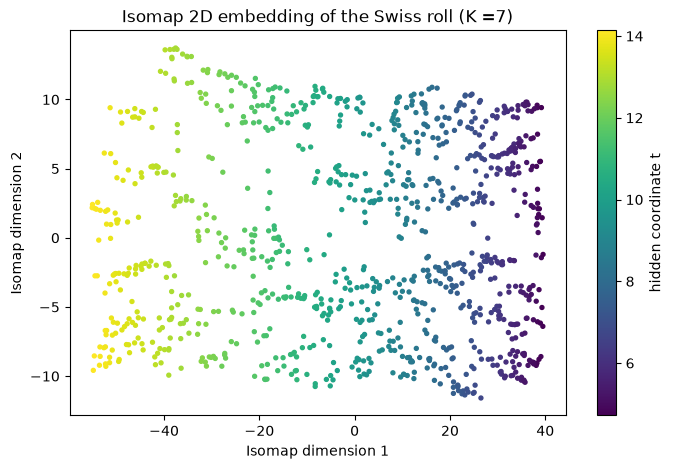

In [6]:
#Step 3 - Classical MDS on the graph distances 
def classical_mds(D, d):
    """ Classical MDS (as described in Tablw 1, Step 3 and note 17 of the paper).
    D: (N x N) matrix as distances between all pairs of points 
    d : number of output demensions
    Returns:
    Y : (N x d) matrix with the new low-dimensional coordinates
    eigvals : all eigenvalues of tau(D), sorted from largest to smallest
    """
    N = D.shape[0]

    #S = matrix of squared distances (note 17)
    S = D **2

    #H = centering matrix : H_ij = delta_ij - 1/N(note 17)
    H = np.eye(N) - np.ones((N, N)) / N

    #tau(D) = -H S H / 2 converts distances into inner products (note 17)
    B = -0.5 * H @ S @ H

    #Eigen-decomposition of the symmetric matrix B
    eigvals, eigvecs = np.linalg.eigh(B)
    order = np.argsort(eigvals)[::-1]
    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]

    #coordinates: y_i^p = sqrt(lamba_p) * v_p^i (Tabole 1, Step 3)
    lam = np.maximum(eigvals[:d], 0)
    Y = eigvecs[:, :d] * np.sqrt(lam)

    return Y, eigvals

#apply classical MDS to the graph distances
Y_iso, eigvals_iso = classical_mds(D_G, d =2)

print("Shape of embedding:", Y_iso.shape)
print("Top 5 eigenvalues:", np.round(eigvals_iso[:5], 1))

#plot the 2D embedding, colored by the hidden coordinate t
plt.figure(figsize=(8, 5))
plt.scatter(Y_iso[:, 0], Y_iso[:, 1], c=t, cmap="viridis", s = 8)
plt.title(f"Isomap 2D embedding of the Swiss roll (K ={K})")
plt.xlabel("Isomap dimension 1")
plt.ylabel("Isomap dimension 2")
plt.colorbar(label="hidden coordinate t")
plt.show()






7. Residual variance for Isomap , PCA and MDS

In [8]:
#residual variance for Isomap, PCA and MDS
from sklearn.decomposition import PCA

def residual_variance(D_hat, Y):
    """Residual variance as defined in note 42 of the paper:
    1 - R^2(D_hat, D_Y)
    D_hat: (N x N) distances that the method tries to preserve
           (D_G for Isomap, D_X for PCA and MDS)
    Y: (N x N) low-dimensional embedding
    R is the linear correlation coefficient over all pairs of points
    """
    D_Y = squareform(pdist(Y))
    upper = np.triu_indices(N, k=1)
    R = np.corrcoef(D_hat[upper], D_Y[upper])[0, 1]
    return 1 - R ** 2

dims = range(1, 11)

#compute each embedding once with 10 dimensions
Y_iso_all, _ = classical_mds(D_G, d=10)
Y_mds_all, _ = classical_mds(D_X, d=10)
Y_pca_all = PCA(n_components=3).fit_transform(X)

rv_iso, rv_mds, rv_pca = [], [], []
for d in dims:
    rv_iso.append(residual_variance(D_G, Y_iso_all[:, :d]))
    rv_mds.append(residual_variance(D_X, Y_mds_all[:, :d]))
    rv_pca.append(residual_variance(D_X, Y_pca_all[:, :min(d,3)]))

#print a table of the results
print("d   Isomap    PCA    MDS")
for d, a, b, c in zip(dims, rv_iso, rv_pca, rv_mds):
    print(f"{d:2d}   {a:.4f}   {b:.4f}   {c:.4f}")

d   Isomap    PCA    MDS
 1   0.0169   0.6138   0.6138
 2   0.0013   0.3296   0.3296
 3   0.0013   0.0000   0.0000
 4   0.0012   0.0000   0.0000
 5   0.0011   0.0000   0.0000
 6   0.0011   0.0000   0.0000
 7   0.0011   0.0000   0.0000
 8   0.0012   0.0000   0.0000
 9   0.0012   0.0000   0.0000
10   0.0012   0.0000   0.0000


8. Reproduction of Fig. 2B (Swiss roll)

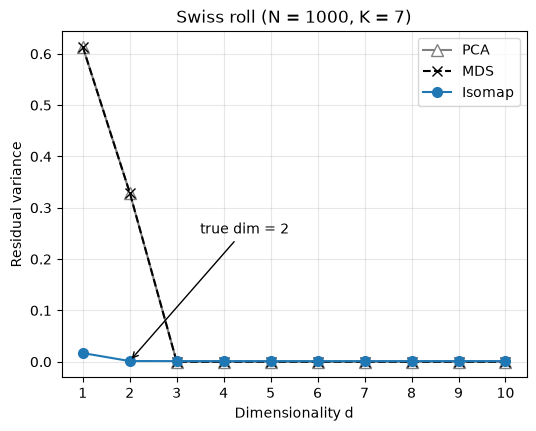

In [9]:
#plot residual variance vs. dimensionality
dims_list = list(dims)

plt.figure(figsize=(6, 4.5))

#same marker style as the paper
plt.plot(dims_list, rv_pca, "^-", color="gray", markerfacecolor="white", markersize=8, label="PCA")
plt.plot(dims_list, rv_mds, "x--", color="black", markersize=7, label="MDS")
plt.plot(dims_list, rv_iso, "o-", color="tab:blue", markersize=7, label="Isomap")

#arrow at the true intrinsic dimensionality (d = 2), as in the paper
plt.annotate("true dim = 2", xy=(2, rv_iso[1]), xytext=(3.5, 0.25), arrowprops=dict(arrowstyle="->"))

plt.xlabel("Dimensionality d")
plt.ylabel("Residual variance")
plt.title(f"Swiss roll (N = {N}, K = {K})")
plt.xticks(dims_list)
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("fig2B_swiss_roll.png", dpi=200, bbox_inches="tight")
plt.show()

9. Verification against scikit-learn's Isomap

In [10]:
#verify our implementation against scikit-learn's Isomap
from sklearn.manifold import Isomap

#run the library implementation with the same parameters
iso_sklearn = Isomap(n_neighbors=K, n_components=2)
Y_sklearn = iso_sklearn.fit_transform(X)

#1.compare the deodesic graph distances computed in step 2
max_diff = np.abs(iso_sklearn.dist_matrix_-D_G).max()
print("Max difference in graph distances D_G:", max_diff)

#2.compare the final 2D coordinates
for k in range(2):
    r = np.corrcoef(Y_iso[:, k], Y_sklearn[:, k])[0, 1]
    print(f"Dimension {k + 1}: |correlation| with scikit-learn = {abs(r):.6f}")
    

Max difference in graph distances D_G: 0.0
Dimension 1: |correlation| with scikit-learn = 1.000000
Dimension 2: |correlation| with scikit-learn = 1.000000


10. MNIST handwritten "2"s (N = 1000)

Number of '2's in MNIST: 6990


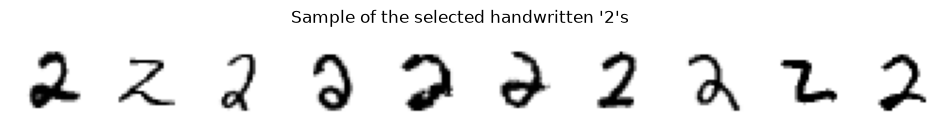

In [11]:
#load 1000 handwritten "2"'s from MNIST
from sklearn.datasets import fetch_openml

#download MNIST
X_all, y_all = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, parser="auto")

#scale pixel values from [0, 255] to [0, 1]
X_all = X_all /255.0

#keep only the images of digit "2"
twos = np.where(y_all == "2")[0]
print("Number of '2's in MNIST:", len(twos))

#rabdomly select N_digits = 100 of them
N_digits = 1000
rng = np.random.RandomState(RANDOM_STATE)
chosen = rng.choice(twos, size = N_digits, replace = False)
X_digits = X_all[chosen]

#show the first 10 selected images
fig, axes = plt.subplots(1, 10, figsize=(12, 1.5))
for ax, img in zip(axes, X_digits[:10]):
    ax.imshow(img.reshape(28, 28), cmap="gray_r")
    ax.axis("off")
plt.suptitle("Sample of the selected handwritten '2's")
plt.show()

11. Reproduction of Fig. 2D (handwritten "2"s)

epsilon-Isomap with Euclidean distances:
   eps = 4.2: 994 components, largest has 2 of 1000 points
   eps = 6.0: 420 components, largest has 479 of 1000 points
   eps = 7.0: 75 components, largest has 921 of 1000 points

K-Isomap (K = 6): connected components =  1

 d    Isomap    PCA    MDS
 1    0.6124    0.7793    0.7793
 2    0.3872    0.6439    0.6439
 3    0.2590    0.5599    0.5599
 4    0.2216    0.4730    0.4730
 5    0.1868    0.3956    0.3956
 6    0.1657    0.3208    0.3208
 7    0.1498    0.2790    0.2790
 8    0.1412    0.2554    0.2554
 9    0.1314    0.2326    0.2326
10    0.1276    0.2092    0.2092


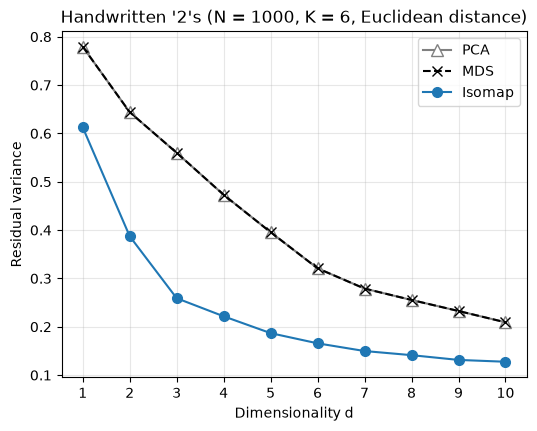

In [13]:
#residual variance on the handwritten "2"s
from sklearn.neighbors import radius_neighbors_graph

#straight-line Euclidean distances between the 784-dimensional images
D_X_dig = squareform(pdist(X_digits))

#1.try epsilon-Isomap as in the paper
print("epsilon-Isomap with Euclidean distances:")
for eps in [4.2, 6.0, 7.0]:
    G_eps = radius_neighbors_graph(X_digits, radius=eps, mode="distance")
    n_comp, labels = connected_components(G_eps, directed = False)
    largest = np.bincount(labels).max()
    print(f"   eps = {eps}: {n_comp} components, largest has {largest} of {N_digits} points")

#2.use K-Isomap instead
K_dig = 6
G_dig = kneighbors_graph(X_digits, n_neighbors = K_dig, mode="distance")
G_dig = G_dig.maximum(G_dig.T)
print(f"\nK-Isomap (K = {K_dig}): connected components = ", connected_components(G_dig, directed= False)[0])

#Isomap step 2 and step 3
D_G_dig = shortest_path(G_dig, method="D", directed= False)
Y_iso_dig, _ = classical_mds(D_G_dig, d=10)

#baselines:classical MDS and PCA on Euclidean distances
Y_mds_dig, _ = classical_mds(D_X_dig, d=10)
Y_pca_dig = PCA(n_components=10).fit_transform(X_digits)

#residual variance for d = 1, ..., 10
N = N_digits
rv_iso_dig = [residual_variance(D_G_dig, Y_iso_dig[:, :d]) for d in dims]
rv_mds_dig = [residual_variance(D_X_dig, Y_mds_dig[:, :d]) for d in dims]
rv_pca_dig = [residual_variance(D_X_dig, Y_pca_dig[:, :d]) for d in dims]

print("\n d    Isomap    PCA    MDS")
for d, a, b, c in zip(dims, rv_iso_dig, rv_pca_dig, rv_mds_dig):
    print(f"{d:2d}    {a:.4f}    {b:.4f}    {c:.4f}")

#plot
plt.figure(figsize=(6, 4.5))
plt.plot(dims_list, rv_pca_dig, "^-", color="gray", markerfacecolor="white",
         markersize=8, label="PCA")
plt.plot(dims_list, rv_mds_dig, "x--", color="black", markersize=7, label="MDS")
plt.plot(dims_list, rv_iso_dig, "o-", color="tab:blue", markersize=7, label="Isomap")
plt.xlabel("Dimensionality d")
plt.ylabel("Residual variance")
plt.title(f"Handwritten '2's (N = {N_digits}, K = {K_dig}, Euclidean distance)")
plt.xticks(dims_list)
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("fig2D_digits.png", dpi=200, bbox_inches="tight")
plt.show()

12. Parameter settings

In [14]:

#table of all parameters used
import pandas as pd

params = [
    ("Both",       "Random seed (random_state)",  RANDOM_STATE,           "not reported"),
    ("Both",       "Output dimensions d",         "1 to 10",              "1 to 10 (Fig. 2)"),
    ("Both",       "Shortest-path algorithm",     "Dijkstra",             "Floyd (note 16)"),
    ("Both",       "Neighborhood graph",          "symmetric (i~j or j~i)", "symmetric (Table 1)"),
    ("Both",       "Evaluation metric",           "1 - R^2 (note 42)",    "1 - R^2 (note 42)"),
    ("Swiss roll", "Number of points N",          N,                      1000),
    ("Swiss roll", "Noise",                       0.0,                    "none"),
    ("Swiss roll", "Neighborhood type",           "K-nearest",            "K-nearest"),
    ("Swiss roll", "K",                           K,                      7),
    ("Swiss roll", "Input distance",              "Euclidean",            "Euclidean"),
    ("Swiss roll", "PCA components",              3,                      "-"),
    ("Digits",     "Number of images N",          N_digits,               1000),
    ("Digits",     "Data source",                 "MNIST (OpenML)",       "MNIST"),
    ("Digits",     "Pixel scaling",               "[0, 1]",               "not reported"),
    ("Digits",     "Neighborhood type",           "K-nearest",            "epsilon-radius"),
    ("Digits",     "K / epsilon",                 f"K = {K_dig}",         "eps = 4.2"),
    ("Digits",     "Input distance",              "Euclidean",            "tangent distance"),
    ("Digits",     "PCA components",              10,                     "-"),
]

table = pd.DataFrame(params, columns=["Experiment", "Parameter",
                                      "Our value", "Paper"])
print(table.to_string(index=False))

Experiment                  Parameter              Our value               Paper
      Both Random seed (random_state)                      0        not reported
      Both        Output dimensions d                1 to 10    1 to 10 (Fig. 2)
      Both    Shortest-path algorithm               Dijkstra     Floyd (note 16)
      Both         Neighborhood graph symmetric (i~j or j~i) symmetric (Table 1)
      Both          Evaluation metric      1 - R^2 (note 42)   1 - R^2 (note 42)
Swiss roll         Number of points N                   1000                1000
Swiss roll                      Noise                    0.0                none
Swiss roll          Neighborhood type              K-nearest           K-nearest
Swiss roll                          K                      7                   7
Swiss roll             Input distance              Euclidean           Euclidean
Swiss roll             PCA components                      3                   -
    Digits         Number of

13. Combined figure for the report

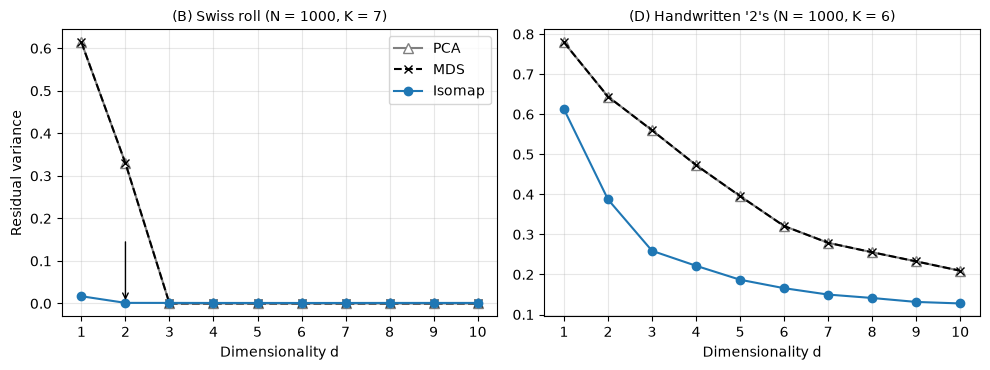

In [15]:
#combined figure for the report
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

#each panel: (axis, panel title, Isomap, PCA, MDS, true dimensionality or None)
panels = [
    (axes[0], f"(B) Swiss roll (N = 1000, K = {K})",
     rv_iso, rv_pca, rv_mds, 2),
    (axes[1], f"(D) Handwritten '2's (N = 1000, K = {K_dig})",
     rv_iso_dig, rv_pca_dig, rv_mds_dig, None),
]

for ax, title, iso, pca, mds, true_dim in panels:
    ax.plot(dims_list, pca, "^-", color="gray", markerfacecolor="white",
            markersize=7, label="PCA")
    ax.plot(dims_list, mds, "x--", color="black", markersize=6, label="MDS")
    ax.plot(dims_list, iso, "o-", color="tab:blue", markersize=6, label="Isomap")

    #arrow at the true dimensionality, only when it is known (as in the paper)
    if true_dim is not None:
        ax.annotate("", xy=(true_dim, iso[true_dim - 1]),
                    xytext=(true_dim, iso[true_dim - 1] + 0.15),
                    arrowprops=dict(arrowstyle="->"))

    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Dimensionality d")
    ax.set_xticks(dims_list)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Residual variance")
axes[0].legend()

plt.tight_layout()
plt.savefig("fig2_reproduced.png", dpi=300, bbox_inches="tight")
plt.show()